In [ ]:
import pandas as pd

# Load the SECOM data, using delim_whitespace=True to handle varying spaces and ensure all rows are read
secom_df = pd.read_csv('/content/secom.data', delim_whitespace=True, header=None)

# Load the SECOM labels
secom_labels_df = pd.read_csv('/content/secom_labels.data', sep=' ', header=None)

print('SECOM Data Head:')
display(secom_df.head())

print('\nSECOM Labels Head:')
display(secom_labels_df.head())

/tmp/ipykernel_10059/1048434321.py:4: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  secom_df = pd.read_csv('/content/secom.data', delim_whitespace=True, header=None)


SECOM Data Head:


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432



SECOM Labels Head:


,0,1
0,-1,19/07/2008 11:55:00
1,-1,19/07/2008 12:32:00
2,1,19/07/2008 13:17:00
3,-1,19/07/2008 14:43:00
4,-1,19/07/2008 15:22:00


In [ ]:
print('SECOM Labels Head:')
display(secom_labels_df.head())

print('\nSECOM Labels Info:')
secom_labels_df.info()

print('\nValue Counts for Labels (Column 0):')
display(secom_labels_df[0].value_counts())

print('\nUnique values in timestamp column (Column 1) and their counts:')
display(secom_labels_df[1].value_counts())

SECOM Labels Head:


,0,1
0,-1,19/07/2008 11:55:00
1,-1,19/07/2008 12:32:00
2,1,19/07/2008 13:17:00
3,-1,19/07/2008 14:43:00
4,-1,19/07/2008 15:22:00



SECOM Labels Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       1567 non-null   int64 
 1   1       1567 non-null   object
dtypes: int64(1), object(1)
memory usage: 24.6+ KB

Value Counts for Labels (Column 0):


,count
0,
-1,1463
1,104



Unique values in timestamp column (Column 1) and their counts:


,count
1,
15/10/2008 01:52:00,3
19/08/2008 18:30:00,2
29/08/2008 05:54:00,2
23/09/2008 06:44:00,2
02/09/2008 03:35:00,2
...,...
29/08/2008 08:45:00,1
29/08/2008 08:41:00,1
29/08/2008 08:20:00,1


In [ ]:
print(f'Shape of secom_df: {secom_df.shape}')
print(f'Shape of secom_labels_df: {secom_labels_df.shape}')

Shape of secom_df: (612, 590)
Shape of secom_labels_df: (1567, 2)


In [ ]:
missing_values_percentage = secom_df.isnull().sum() / len(secom_df) * 100
missing_values_percentage = missing_values_percentage[missing_values_percentage > 0].sort_values(ascending=False)

print('Percentage of Missing Values in secom_df:')
display(missing_values_percentage)

Percentage of Missing Values in secom_df:


,0
246,100.000000
109,100.000000
111,100.000000
110,100.000000
85,100.000000
...,...
6,0.163399
5,0.163399
4,0.163399
3,0.163399


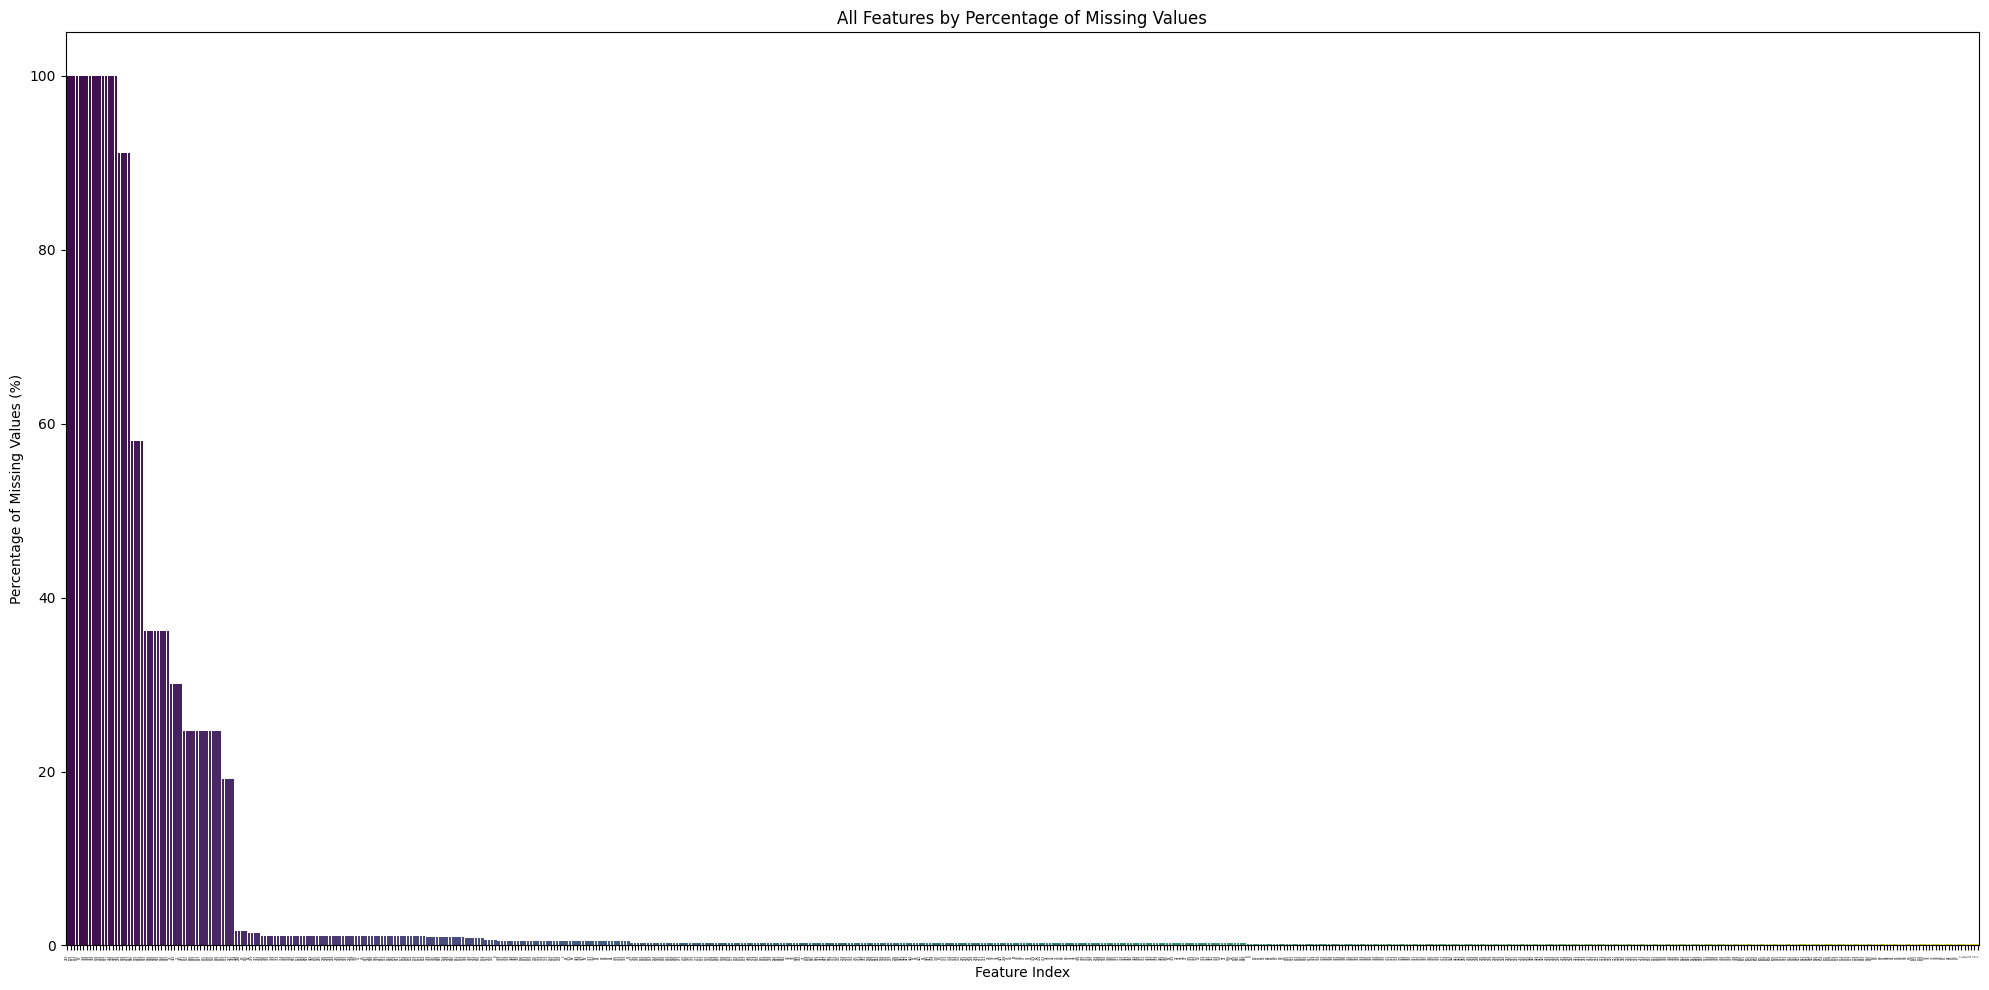

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use all features with missing values
all_missing_features = missing_values_percentage

plt.figure(figsize=(20, 10)) # Increase figure size for more features
sns.barplot(x=all_missing_features.index.astype(str), y=all_missing_features.values, hue=all_missing_features.index.astype(str), palette='viridis', legend=False)
plt.title('All Features by Percentage of Missing Values')
plt.xlabel('Feature Index')
plt.ylabel('Percentage of Missing Values (%)')
plt.xticks(rotation=90, fontsize=2) # Further reduce font size for x-ticks
plt.tight_layout()
plt.show()

### Imputation of Missing Values

I will now impute the missing values in `secom_df` using two different strategies:

1.  **Channel-wise Mean Imputation**: Replace `NaN` values in each column with the mean of that column.
2.  **Channel-wise Median Imputation**: Replace `NaN` values in each column with the median of that column.

In [ ]:
# Mean Imputation
secom_df_mean_imputed = secom_df.fillna(secom_df.mean())

print('SECOM Data (Mean Imputed) Head:')
display(secom_df_mean_imputed.head())

SECOM Data (Mean Imputed) Head:


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,0.005451,99.922616,0.5005,0.0118,0.0035,2.3630,0.019486,0.017212,0.005527,110.661091
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.006000,208.204500,0.5019,0.0223,0.0055,4.4447,0.009600,0.020100,0.006000,208.204500
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.014800,82.860200,0.4958,0.0157,0.0039,3.1745,0.058400,0.048400,0.014800,82.860200
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.004400,73.843200,0.4990,0.0103,0.0025,2.0544,0.020200,0.014900,0.004400,73.843200
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,0.005451,99.922616,0.4800,0.4766,0.1045,99.3032,0.020200,0.014900,0.004400,73.843200


In [ ]:
# Median Imputation
secom_df_median_imputed = secom_df.fillna(secom_df.median())

print('\nSECOM Data (Median Imputed) Head:')
display(secom_df_median_imputed.head())


SECOM Data (Median Imputed) Head:


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,0.0048,76.6094,0.5005,0.0118,0.0035,2.3630,0.0193,0.01565,0.0049,77.7519
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.02010,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.04840,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.01490,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,0.0048,76.6094,0.4800,0.4766,0.1045,99.3032,0.0202,0.01490,0.0044,73.8432


Let's check if there are any remaining missing values in the imputed DataFrames.

In [ ]:
print('Missing values in secom_df_mean_imputed:', secom_df_mean_imputed.isnull().sum().sum())
print('Missing values in secom_df_median_imputed:', secom_df_median_imputed.isnull().sum().sum())

Missing values in secom_df_mean_imputed: 9792
Missing values in secom_df_median_imputed: 9792


### Standardizing the Data

Now, I will standardize both the mean-imputed and median-imputed DataFrames using `StandardScaler`. This process transforms the data such that it has a mean of 0 and a standard deviation of 1, which is often a requirement for many machine learning algorithms.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Apply StandardScaler to the mean-imputed DataFrame
secom_df_mean_scaled = pd.DataFrame(scaler.fit_transform(secom_df_mean_imputed), columns=secom_df_mean_imputed.columns)

print('SECOM Data (Mean Imputed & Scaled) Head:')
display(secom_df_mean_scaled.head())

SECOM Data (Mean Imputed & Scaled) Head:


/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,0.403127,0.745953,-0.461409,0.310388,0.318473,0.0,-1.301041,1.033427,0.275271,1.102871,...,0.000000,0.000000,0.047156,-0.207486,-0.117672,-0.199687,0.000000,0.000000,0.000000,1.397455e-16
1,1.412535,-0.353772,1.048690,0.501244,-1.414484,0.0,0.047603,1.295103,0.215714,0.027167,...,0.314404,1.963380,0.437007,0.335162,0.359904,0.317556,-0.891767,0.346535,0.183266,9.592144e-01
2,-1.127251,0.700789,-0.508181,1.352661,0.808194,0.0,-1.907075,0.981092,-0.593642,0.323469,...,5.353779,-0.309378,-1.261628,-0.005931,-0.022156,0.001948,3.510282,3.741869,3.593229,-2.733861e-01
3,-0.253883,-0.189581,-0.061677,-1.510957,0.188534,0.0,0.587460,-0.274952,0.087439,-0.739352,...,-0.601846,-0.472875,-0.370541,-0.285007,-0.356460,-0.276365,0.064416,-0.277342,-0.436727,-3.620568e-01
4,0.423517,0.065939,1.152850,0.003013,0.883937,0.0,-0.507422,0.667081,0.314975,-0.140307,...,0.000000,0.000000,-5.661370,23.813734,23.999919,23.887156,0.064416,-0.277342,-0.436727,-3.620568e-01


In [ ]:
# Apply StandardScaler to the median-imputed DataFrame
secom_df_median_scaled = pd.DataFrame(scaler.fit_transform(secom_df_median_imputed), columns=secom_df_median_imputed.columns)

print('\nSECOM Data (Median Imputed & Scaled) Head:')
display(secom_df_median_scaled.head())


SECOM Data (Median Imputed & Scaled) Head:


/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,0.403236,0.745769,-0.461235,0.310642,0.318228,0.0,-1.301004,1.033681,0.275250,1.102880,...,-0.153961,-0.173772,0.047093,-0.207193,-0.117442,-0.199403,-0.016715,-0.186737,-0.242162,-0.322507
1,1.412643,-0.353952,1.048850,0.501494,-1.414699,0.0,0.047640,1.295350,0.215694,0.027176,...,0.521883,2.162032,0.436944,0.335448,0.360130,0.317833,-0.891712,0.347128,0.184043,0.960108
2,-1.127141,0.700606,-0.508007,1.352894,0.807940,0.0,-1.907038,0.981347,-0.593663,0.323477,...,5.478070,-0.062821,-1.261690,-0.005641,-0.021928,0.002228,3.510336,3.742267,3.593678,-0.272282
3,-0.253774,-0.189762,-0.061507,-1.510665,0.188291,0.0,0.587496,-0.274668,0.087418,-0.739344,...,-0.379242,-0.222872,-0.370604,-0.284713,-0.356228,-0.276081,0.064471,-0.276714,-0.435891,-0.360938
4,0.423626,0.065757,1.153009,0.003273,0.883682,0.0,-0.507386,0.667343,0.314954,-0.140299,...,-0.153961,-0.173772,-5.661430,23.813719,23.999957,23.887150,0.064471,-0.276714,-0.435891,-0.360938


### Data Splitting

I will now split the preprocessed data into training, validation, and test sets with a 70:10:20 ratio.

First, I'll extract the actual labels (the first column) from `secom_labels_df`.

In [ ]:
labels = secom_labels_df[0]

print('Value Counts for Labels:')
display(labels.value_counts())

print('\nData type of labels:')
print(labels.dtype)

Value Counts for Labels:


,count
0,
-1,1463
1,104



Data type of labels:
int64


In [ ]:
labels = secom_labels_df[0]

print('Value Counts for Labels:')
display(labels.value_counts())

print('\nData type of labels:')
print(labels.dtype)

# ----------------------------------
# Convert labels from {-1, 1} to {0, 1}
# ----------------------------------
labels = labels.replace({
    -1: 0,
     1: 1
})

print('\nValue Counts After Conversion:')
display(labels.value_counts())

print('\nUnique Labels:')
print(labels.unique())

Value Counts for Labels:


,count
0,
-1,1463
1,104



Data type of labels:
int64

Value Counts After Conversion:


,count
0,
0,1463
1,104



Unique Labels:
[0 1]


Now, let's split the mean-imputed and scaled data.

Next, I'll split the median-imputed and scaled data.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)


def to_tensor_dataset(X, y):
    X = torch.tensor(X.values if hasattr(X, "values") else X, dtype=torch.float32)
    y = torch.tensor(y.values if hasattr(y, "values") else y, dtype=torch.long)
    return X, y


def train_mlp_pytorch(X_train, X_val, X_test, y_train, y_val, y_test, name):
    X_train, y_train = to_tensor_dataset(X_train, y_train)
    X_val, y_val = to_tensor_dataset(X_val, y_val)
    X_test, y_test = to_tensor_dataset(X_test, y_test)

    train_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_train, y_train),
        batch_size=32,
        shuffle=True
    )

    model = MLP(input_dim=X_train.shape[1]).to(device)

    # SECOM은 클래스 불균형이 심하므로 class weight 사용
    class_counts = torch.bincount(y_train)
    class_weights = len(y_train) / (2.0 * class_counts.float())
    class_weights = class_weights.to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

    best_val_f1 = 0
    best_state = None

    for epoch in range(100):
        model.train()
        total_loss = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # validation
        model.eval()
        with torch.no_grad():
            val_logits = model(X_val.to(device))
            val_pred = torch.argmax(val_logits, dim=1).cpu().numpy()

        val_f1 = f1_score(y_val.numpy(), val_pred, average="macro")

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = model.state_dict()

        if (epoch + 1) % 10 == 0:
            print(f"[{name}] Epoch {epoch+1:03d} | Loss: {total_loss:.4f} | Val Macro-F1: {val_f1:.4f}")

    model.load_state_dict(best_state)

    # test
    model.eval()
    with torch.no_grad():
        test_logits = model(X_test.to(device))
        test_pred = torch.argmax(test_logits, dim=1).cpu().numpy()

    y_test_np = y_test.numpy()

    print(f"\n===== {name} Test Result =====")
    print("Accuracy:", accuracy_score(y_test_np, test_pred))
    print("Macro-F1:", f1_score(y_test_np, test_pred, average="macro"))
    print("\nClassification Report:")
    print(classification_report(y_test_np, test_pred))

    return model

In [ ]:
model_mean = train_mlp_pytorch(
    X_mean_train, X_mean_val, X_mean_test,
    y_mean_train, y_mean_val, y_mean_test,
    name="Mean Imputation"
)

model_median = train_mlp_pytorch(
    X_median_train, X_median_val, X_median_test,
    y_median_train, y_median_val, y_median_test,
    name="Median Imputation"
)

NameError: name 'X_mean_train' is not defined

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(secom_df_mean_scaled)

plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[labels==0,0],
    X_pca[labels==0,1],
    s=10,
    alpha=0.5,
    label="Normal"
)

plt.scatter(
    X_pca[labels==1,0],
    X_pca[labels==1,1],
    s=30,
    alpha=0.8,
    label="Fail"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("SECOM PCA Visualization")
plt.legend()
plt.show()

In [ ]:
feature_idx = 0

plt.figure(figsize=(8,4))
plt.boxplot(secom_df_mean_scaled.iloc[:, feature_idx])
plt.title(f"Feature {feature_idx}")
plt.show()

In [ ]:
import pandas as pd

df = pd.DataFrame(secom_df_mean_scaled)

Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask = (df < lower) | (df > upper)

outlier_count = outlier_mask.sum(axis=1)

print(outlier_count.describe())

In [ ]:
threshold = outlier_count.quantile(0.95)

iqr_pred = (outlier_count >= threshold).astype(int)

print(pd.Series(iqr_pred).value_counts())

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[iqr_pred==0,0],
    X_pca[iqr_pred==0,1],
    s=10,
    alpha=0.4,
    label="Normal"
)

plt.scatter(
    X_pca[iqr_pred==1,0],
    X_pca[iqr_pred==1,1],
    marker='x',
    s=40,
    label="IQR Anomaly"
)

plt.legend()
plt.title("IQR-based Outlier Detection")
plt.show()

In [ ]:
print("Number of IQR anomalies:", (iqr_pred == 1).sum())

In [ ]:
anomaly_idx = np.where(iqr_pred == 1)[0]

print("Anomaly Indices:")
print(anomaly_idx)

In [ ]:
anomaly_df = pd.DataFrame({
    "Index": anomaly_idx,
    "Outlier_Count": outlier_count.iloc[anomaly_idx],
    "Label": labels.iloc[anomaly_idx]
})

display(anomaly_df)

NameError: name 'anomaly_idx' is not defined

In [ ]:
print("Fail ratio among anomalies:")
print(anomaly_df["Label"].mean())

Fail ratio among anomalies:


NameError: name 'anomaly_df' is not defined